<a href="https://colab.research.google.com/github/Mani47e/Scream_Detection/blob/main/Scream_det.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aananehsansiam/audio-dataset-of-scream-and-non-scream")

print("Path to dataset files:", path)

100%|██████████| 333M/333M [00:02<00:00, 140MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/aananehsansiam/audio-dataset-of-scream-and-non-scream/versions/1


In [4]:
import os
import glob

# Check what folders are inside the dataset path
print("Subfolders / Files:")
for item in os.listdir(path):
    print(" -", item)

# Find all audio files recursively
audio_files = glob.glob(os.path.join(path, "**", "*.*"), recursive=True)
audio_files = [f for f in audio_files if f.lower().endswith(('.wav', '.mp3', '.ogg', '.flac'))]

print(f"\nTotal audio files found: {len(audio_files)}")

# Show a few sample paths to see the structure
print("\nSample file paths:")
for p in audio_files[:5]:
    print(" ", p)

Subfolders / Files:
 - Converted_Separately

Total audio files found: 3128

Sample file paths:
  /root/.cache/kagglehub/datasets/aananehsansiam/audio-dataset-of-scream-and-non-scream/versions/1/Converted_Separately/scream/1155.wav
  /root/.cache/kagglehub/datasets/aananehsansiam/audio-dataset-of-scream-and-non-scream/versions/1/Converted_Separately/scream/716.wav
  /root/.cache/kagglehub/datasets/aananehsansiam/audio-dataset-of-scream-and-non-scream/versions/1/Converted_Separately/scream/454.wav
  /root/.cache/kagglehub/datasets/aananehsansiam/audio-dataset-of-scream-and-non-scream/versions/1/Converted_Separately/scream/447.wav
  /root/.cache/kagglehub/datasets/aananehsansiam/audio-dataset-of-scream-and-non-scream/versions/1/Converted_Separately/scream/852.wav


In [5]:
import librosa
import soundfile as sf

# Set paths to the two categories
base_dir = os.path.join(path, "Converted_Separately")
scream_files = sorted(glob.glob(os.path.join(base_dir, "scream", "*.wav")))
non_scream_files = sorted(glob.glob(os.path.join(base_dir, "non_scream", "*.wav")))

print(f"Class 1 (Scream):     {len(scream_files)} files")
print(f"Class 0 (Non-Scream): {len(non_scream_files)} files")

# Inspect one sample file without changing anything (sr=None keeps original sample rate)
sample_file = scream_files[0]
info = sf.info(sample_file)

print(f"\n--- Sample Audio Info ({os.path.basename(sample_file)}) ---")
print(f"Sampling Rate:    {info.samplerate} Hz")
print(f"Duration:         {info.duration:.3f} seconds")
print(f"Channels:         {info.channels} ({'Stereo' if info.channels == 2 else 'Mono'})")
print(f"Format / Subtype: {info.format} / {info.subtype}")

Class 1 (Scream):     1583 files
Class 0 (Non-Scream): 1545 files

--- Sample Audio Info (1.wav) ---
Sampling Rate:    16000 Hz
Duration:         1.188 seconds
Channels:         2 (Stereo)
Format / Subtype: WAV / PCM_16


Original length:     36800 samples (2.300 s)
Processed length:    16000 samples (1.000 s)


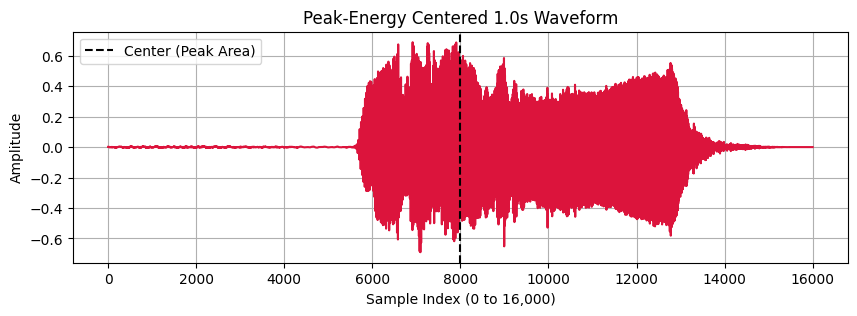

In [6]:
import numpy as np
import matplotlib.pyplot as plt

TARGET_SR = 16000
TARGET_DURATION = 1.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)  # 16000

def standardize_audio_peak_centered(file_path):
    """
    1. Loads audio and forces mono @ 16 kHz.
    2. Finds the highest energy point (peak).
    3. Centers the 1.0-second (16000 samples) window around that peak.
    """
    y, sr = librosa.load(file_path, sr=TARGET_SR, mono=True)
    orig_len = len(y)

    if orig_len == 0:
        return np.zeros(TARGET_SAMPLES, dtype=np.float32), 0

    # Smooth amplitude envelope to find the center of energy (window of 50ms)
    window_len = int(0.05 * TARGET_SR) # 800 samples
    energy = np.convolve(y**2, np.ones(window_len)/window_len, mode='same')
    peak_idx = int(np.argmax(energy))

    half_window = TARGET_SAMPLES // 2  # 8000 samples

    if orig_len >= TARGET_SAMPLES:
        # Determine start and end centered on the peak
        start = peak_idx - half_window
        end = start + TARGET_SAMPLES

        # Boundary checks: if peak is too close to start or end
        if start < 0:
            start = 0
            end = TARGET_SAMPLES
        elif end > orig_len:
            end = orig_len
            start = end - TARGET_SAMPLES

        y_centered = y[start:end]
    else:
        # If audio is shorter than 16000, pad symmetrically
        pad_needed = TARGET_SAMPLES - orig_len
        pad_left = pad_needed // 2
        pad_right = pad_needed - pad_left
        y_centered = np.pad(y, (pad_left, pad_right), mode='constant')

    return y_centered, orig_len

# Test on a scream file
centered_audio, orig_len = standardize_audio_peak_centered(scream_files[99])

print(f"Original length:     {orig_len} samples ({orig_len / TARGET_SR:.3f} s)")
print(f"Processed length:    {len(centered_audio)} samples ({len(centered_audio) / TARGET_SR:.3f} s)")

# Visualize the centered waveform
plt.figure(figsize=(10, 3))
plt.plot(centered_audio, color='crimson')
plt.axvline(x=TARGET_SAMPLES // 2, color='black', linestyle='--', label='Center (Peak Area)')
plt.title("Peak-Energy Centered 1.0s Waveform")
plt.xlabel("Sample Index (0 to 16,000)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

Log-Mel Spectrogram Shape: (51, 40)  (Time steps: 49, Mel frequency bins: 40)


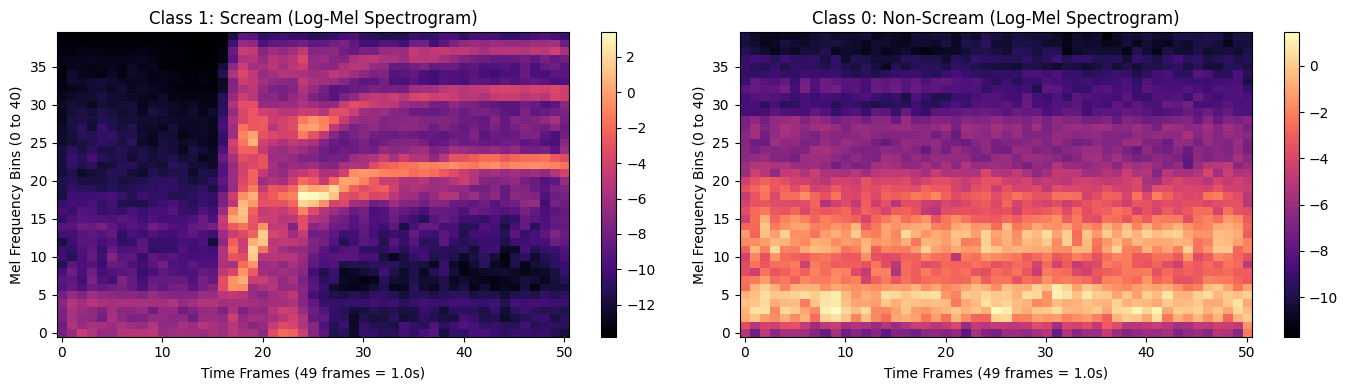

In [7]:
import librosa.display

def compute_log_mel_spectrogram(y):
    """
    Computes Log-Mel Spectrogram from 1-second audio array.
    Output shape: (49, 40)
    """
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=TARGET_SR,
        n_fft=512,
        hop_length=320,
        win_length=480,
        n_mels=40,
        fmin=100.0,
        fmax=8000.0,
        power=2.0
    )
    # Log scale: log(energy + epsilon)
    log_mel = np.log(mel + 1e-6)

    # Transpose so time is on the X-axis (49, 40)
    return log_mel.T

# 1. Process 1 Scream sample
scream_audio, _ = standardize_audio_peak_centered(scream_files[1])
scream_mel = compute_log_mel_spectrogram(scream_audio)

# 2. Process 1 Non-Scream sample
non_scream_audio, _ = standardize_audio_peak_centered(non_scream_files[8])
non_scream_mel = compute_log_mel_spectrogram(non_scream_audio)

print(f"Log-Mel Spectrogram Shape: {scream_mel.shape}  (Time steps: 49, Mel frequency bins: 40)")

# Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

im1 = axes[0].imshow(scream_mel.T, aspect='auto', origin='lower', cmap='magma')
axes[0].set_title("Class 1: Scream (Log-Mel Spectrogram)")
axes[0].set_xlabel("Time Frames (49 frames = 1.0s)")
axes[0].set_ylabel("Mel Frequency Bins (0 to 40)")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(non_scream_mel.T, aspect='auto', origin='lower', cmap='magma')
axes[1].set_title("Class 0: Non-Scream (Log-Mel Spectrogram)")
axes[1].set_xlabel("Time Frames (49 frames = 1.0s)")
axes[1].set_ylabel("Mel Frequency Bins (0 to 40)")
fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

X = []
y = []

print("1/2: Processing Scream files...")
for file_path in tqdm(scream_files):
    audio, orig_len = standardize_audio_peak_centered(file_path)
    if orig_len > 0:
        mel = compute_log_mel_spectrogram(audio)
        X.append(mel)
        y.append(1)  # Class 1: Scream

print("\n2/2: Processing Non-Scream files...")
for file_path in tqdm(non_scream_files):
    audio, orig_len = standardize_audio_peak_centered(file_path)
    if orig_len > 0:
        mel = compute_log_mel_spectrogram(audio)
        X.append(mel)
        y.append(0)  # Class 0: Non-Scream

# Convert to NumPy arrays
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

# Add the 1 channel dimension for CNN: (N, 49, 40, 1)
X = np.expand_dims(X, axis=-1)

print(f"\nTotal Dataset Shape: X = {X.shape}, y = {y.shape}")

# Stratified Split: 80% Train, 10% Validation, 10% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train set:      {X_train.shape[0]} samples (Screams: {np.sum(y_train == 1)})")
print(f"Validation set: {X_val.shape[0]} samples (Screams: {np.sum(y_val == 1)})")
print(f"Test set:       {X_test.shape[0]} samples (Screams: {np.sum(y_test == 1)})")

# Save to disk so we never have to recompute this
np.savez_compressed(
    "dataset_features.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test
)

print("\nSaved features successfully to 'dataset_features.npz'!")

1/2: Processing Scream files...


  0%|          | 0/1583 [00:00<?, ?it/s]


2/2: Processing Non-Scream files...


  0%|          | 0/1545 [00:00<?, ?it/s]


Total Dataset Shape: X = (3128, 51, 40, 1), y = (3128,)
Train set:      2502 samples (Screams: 1266)
Validation set: 313 samples (Screams: 159)
Test set:       313 samples (Screams: 158)

Saved features successfully to 'dataset_features.npz'!


In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_lwp_model(input_shape=(49, 40, 1)):
    """
    LwP (Lightweight Partitioned) Architecture:
    C1: Conv1 - Conv2 - Conv3 - Projection
    C2: GRU - Dense
    """
    inputs = layers.Input(shape=input_shape, name="mel_input")

    # ==========================================
    # Component 1: CNN Feature Extractor
    # ==========================================
    # Conv 1: Detects low-level onset edges
    x = layers.Conv2D(16, kernel_size=(3, 3), padding="same", name="conv1")(inputs)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.ReLU(name="relu1")(x)
    x = layers.MaxPool2D(pool_size=(2, 2), name="pool1")(x) # Reduces size to (24, 20)

    # Conv 2: Detects mid-level harmonic lines
    x = layers.Conv2D(32, kernel_size=(3, 3), padding="same", name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.ReLU(name="relu2")(x)
    x = layers.MaxPool2D(pool_size=(2, 2), name="pool2")(x) # Reduces size to (12, 10)

    # Conv 3: Detects high-level harmonic stacks
    x = layers.Conv2D(48, kernel_size=(3, 3), padding="same", name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.ReLU(name="relu3")(x)
    x = layers.MaxPool2D(pool_size=(1, 2), name="pool3")(x) # Downsamples frequency only -> (12, 5)

    # Bridge between 2D CNN and Sequential GRU:
    # Reshape (12, 5, 48) -> (12, 5 * 48 = 240)
    time_steps = x.shape[1]
    feature_dim = x.shape[2] * x.shape[3]
    x = layers.Reshape((time_steps, feature_dim), name="reshape_for_recurrent")(x)

    # Projection layer: Compresses 240 features down to 32 before GRU
    x = layers.Dense(32, activation="relu", name="projection")(x)
    x = layers.Dropout(0.2, name="dropout_proj")(x)

    # ==========================================
    # Component 2: Temporal Classifier (GRU + Dense)
    # ==========================================
    # GRU: Tracks sound evolution over the 12 time slices
    x = layers.GRU(32, return_sequences=False, name="gru")(x)
    x = layers.Dropout(0.2, name="dropout_gru")(x)

    # Final Classification: 1 unit with sigmoid (0 = Non-Scream, 1 = Scream)
    outputs = layers.Dense(1, activation="sigmoid", name="dense_output")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="LwP_Scream_Model")
    return model

# Instantiate and inspect the architecture
model = build_lwp_model()
model.summary()

Model: "LwP_Scream_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mel_input (InputLayer)          │ (None, 49, 40, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 49, 40, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 49, 40, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 49, 40, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 24, 20, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 20, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 24, 20, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 24, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 12, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 12, 10, 48)     │        13,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 12, 10, 48)     │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 12, 10, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 12, 5, 48)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_for_recurrent (Reshape) │ (None, 12, 240)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ projection (Dense)              │ (None, 12, 32)         │         7,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_proj (Dropout)          │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_gru (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_output (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,137 (129.44 KB)

 Trainable params: 32,945 (128.69 KB)

 Non-trainable params: 192 (768.00 B)

In [11]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import callbacks

# 1. Load the preprocessed features
data = np.load("dataset_features.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

# 2. Ensure the 1-channel dimension is present: (N, 51, 40, 1)
if len(X_train.shape) == 3:
    X_train = np.expand_dims(X_train, axis=-1)
    X_val = np.expand_dims(X_val, axis=-1)
    X_test = np.expand_dims(X_test, axis=-1)

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")

# 3. Rebuild the model matching the exact input shape: (51, 40, 1)
model = build_lwp_model(input_shape=X_train.shape[1:])

# 4. Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# 5. Callbacks
my_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        "best_lwp_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# 6. Train!
EPOCHS = 40
BATCH_SIZE = 32

print("\n--- Starting Training ---")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=my_callbacks
)

print("\nTraining complete! Best model saved to 'best_lwp_model.keras'.")

X_train shape: (2502, 51, 40, 1)
X_val shape:   (313, 51, 40, 1)
X_test shape:  (313, 51, 40, 1)

--- Starting Training ---
Epoch 1/40
78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.7972 - loss: 0.4481 - precision: 0.7909 - recall: 0.8480
Epoch 1: val_loss improved from None to 0.37548, saving model to best_lwp_model.keras

Epoch 1: finished saving model to best_lwp_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.8605 - loss: 0.3453 - precision: 0.8585 - recall: 0.8673 - val_accuracy: 0.8498 - val_loss: 0.3755 - val_precision: 0.8636 - val_recall: 0.8365 - learning_rate: 0.0010
Epoch 2/40
78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9173 - loss: 0.2341 - precision: 0.9344 - recall: 0.9006
Epoch 2: val_loss improved from 0.37548 to 0.20592, saving model to best_lwp_model.keras

Epoch 2: finished saving model to best_lwp_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - accuracy: 0.9245 - loss: 0.2155 - precision: 0.9396 - recall: 0.9092 - val_ac

          TEST SET EVALUATION RESULTS        
 Test Loss:      0.2145
 Test Accuracy:  91.69%
 Test Precision: 90.24%
 Test Recall:    93.67%

Classification Report:
                precision    recall  f1-score   support

Non-Scream (0)     0.9329    0.8968    0.9145       155
    Scream (1)     0.9024    0.9367    0.9193       158

      accuracy                         0.9169       313
     macro avg     0.9177    0.9167    0.9169       313
  weighted avg     0.9175    0.9169    0.9169       313



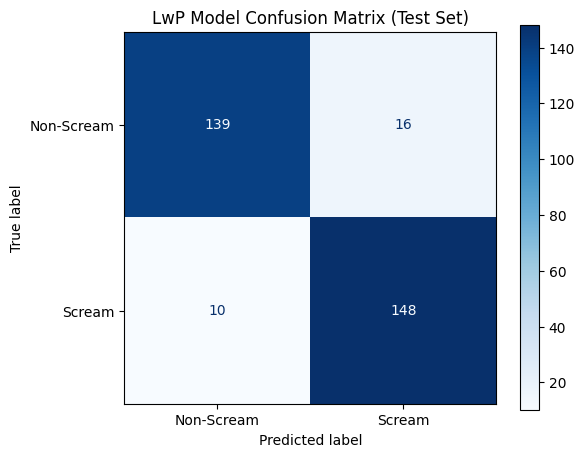

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load the best saved model weights
best_model = tf.keras.models.load_model("best_lwp_model.keras")

# 2. Evaluate on the Test Set
test_loss, test_acc, test_prec, test_rec = best_model.evaluate(X_test, y_test, verbose=0)

print("=" * 45)
print("          TEST SET EVALUATION RESULTS        ")
print("=" * 45)
print(f" Test Loss:      {test_loss:.4f}")
print(f" Test Accuracy:  {test_acc * 100:.2f}%")
print(f" Test Precision: {test_prec * 100:.2f}%")
print(f" Test Recall:    {test_rec * 100:.2f}%")
print("=" * 45)

# 3. Predict class probabilities
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# 4. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Non-Scream (0)", "Scream (1)"], digits=4))

# 5. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Scream", "Scream"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("LwP Model Confusion Matrix (Test Set)")
plt.grid(False)
plt.show()

In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

# 1. Define LwP model with unroll=True for Microcontrollers
def build_unrolled_lwp_model(input_shape=(51, 40, 1)):
    inputs = layers.Input(shape=input_shape, batch_size=1, name="mel_input") # Fixed batch=1 for MCU

    # C1: CNN
    x = layers.Conv2D(16, (3, 3), padding="same", name="conv1")(inputs)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.ReLU(name="relu1")(x)
    x = layers.MaxPool2D((2, 2), name="pool1")(x)

    x = layers.Conv2D(32, (3, 3), padding="same", name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.ReLU(name="relu2")(x)
    x = layers.MaxPool2D((2, 2), name="pool2")(x)

    x = layers.Conv2D(48, (3, 3), padding="same", name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.ReLU(name="relu3")(x)
    x = layers.MaxPool2D((1, 2), name="pool3")(x)

    time_steps = x.shape[1]
    feature_dim = x.shape[2] * x.shape[3]
    x = layers.Reshape((time_steps, feature_dim), name="reshape_for_recurrent")(x)

    x = layers.Dense(32, activation="relu", name="projection")(x)
    x = layers.Dropout(0.2, name="dropout_proj")(x)

    # C2: GRU (unroll=True eliminates dynamic TensorList ops!)
    x = layers.GRU(32, return_sequences=False, unroll=True, name="gru")(x)
    x = layers.Dropout(0.2, name="dropout_gru")(x)

    outputs = layers.Dense(1, activation="sigmoid", name="dense_output")(x)

    return models.Model(inputs=inputs, outputs=outputs, name="LwP_Unrolled")

# 2. Build unrolled model and transfer the trained weights
unrolled_model = build_unrolled_lwp_model()
trained_model = tf.keras.models.load_model("best_lwp_model.keras")
unrolled_model.set_weights(trained_model.get_weights())
print("Transferred trained weights into unrolled microcontroller model!")

# 3. Representative data generator
def representative_data_gen():
    indices = np.random.choice(len(X_train), size=150, replace=False)
    for idx in indices:
        sample = np.expand_dims(X_train[idx], axis=0).astype(np.float32)
        yield [sample]

# 4. Quantize to full INT8
converter = tf.lite.TFLiteConverter.from_keras_model(unrolled_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

print("Converting to INT8 TFLite...")
tflite_quant_model = converter.convert()

with open("scream_lwp_int8.tflite", "wb") as f:
    f.write(tflite_quant_model)

size_kb = len(tflite_quant_model) / 1024.0
print(f" Successfully saved scream_lwp_int8.tflite! Size: {size_kb:.2f} KB")

Transferred trained weights into unrolled microcontroller model!
Converting to INT8 TFLite...
Saved artifact at '/tmp/tmpah14ix3t'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 51, 40, 1), dtype=tf.float32, name='mel_input')
Output Type:
  TensorSpec(shape=(1, 1), dtype=tf.float32, name=None)
Captures:
  134887029354384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887029355152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887030615184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887030613264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887029353616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887030614800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887030604048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887030607504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134887030616336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


 Successfully saved scream_lwp_int8.tflite! Size: 125.41 KB


In [21]:
from google.colab import files

with open("scream_lwp_int8.tflite", "rb") as f:
    tflite_bytes = f.read()

model_len = len(tflite_bytes)

# 1. Generate scream_model_data.h
header_content = """#ifndef SCREAM_MODEL_DATA_H_
#define SCREAM_MODEL_DATA_H_

#include <cstdint>

extern const unsigned int g_scream_model_data_size;
extern const unsigned char g_scream_model_data[];

#endif // SCREAM_MODEL_DATA_H_
"""

with open("scream_model_data.h", "w") as f:
    f.write(header_content)

# 2. Generate scream_model_data.cc
hex_lines = [f"0x{b:02x}" for b in tflite_bytes]
formatted_hex = ",\n  ".join([", ".join(hex_lines[i:i+12]) for i in range(0, len(hex_lines), 12)])

cc_content = f"""#include <cstdint>
#include "scream_model_data.h"

const unsigned int g_scream_model_data_size = {model_len};
alignas(16) const unsigned char g_scream_model_data[] = {{
  {formatted_hex}
}};
"""

with open("scream_model_data.cc", "w") as f:
    f.write(cc_content)

print(f"Generated scream_model_data.h and scream_model_data.cc ({model_len} bytes)!")

# 3. Automatically download to your computer
files.download("scream_model_data.h")
files.download("scream_model_data.cc")
files.download("scream_lwp_int8.tflite")

Generated scream_model_data.h and scream_model_data.cc (128416 bytes)!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload your audio file (.wav or .mp3):


Saving Record (online-voice-recorder.com).mp3 to Record (online-voice-recorder.com) (2).mp3

--- Testing: Record (online-voice-recorder.com) (2).mp3 ---
🚨 RESULT: SCREAM DETECTED! (Confidence: 89.2%)
Audio fed to model:


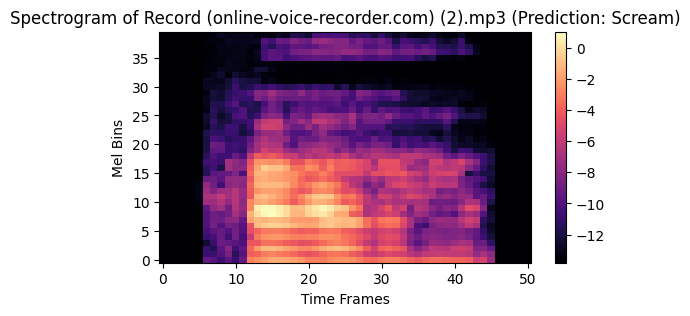

In [24]:
from google.colab import files
import IPython.display as ipd

print("Upload your audio file (.wav or .mp3):")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\n--- Testing: {filename} ---")

    # 1. Standardize (force 16 kHz mono, peak-center to 1.0 sec)
    custom_audio, orig_len = standardize_audio_peak_centered(filename)

    # 2. Extract Log-Mel Spectrogram (51, 40, 1)
    custom_mel = compute_log_mel_spectrogram(custom_audio)
    custom_input = np.expand_dims(custom_mel, axis=(0, -1)).astype(np.float32) # Shape: (1, 51, 40, 1)

    # 3. Predict with your trained model
    prob = float(best_model.predict(custom_input, verbose=0)[0][0])

    # 4. Display results
    print("=" * 40)
    if prob >= 0.5:
        print(f"🚨 RESULT: SCREAM DETECTED! (Confidence: {prob*100:.1f}%)")
    else:
        print(f"✅ RESULT: NON-SCREAM (Confidence: {(1-prob)*100:.1f}%)")
    print("=" * 40)

    # Play the 1-second audio that the model analyzed
    print("Audio fed to model:")
    ipd.display(ipd.Audio(custom_audio, rate=TARGET_SR))

    # Plot its spectrogram
    plt.figure(figsize=(6, 3))
    plt.imshow(custom_mel.T, aspect='auto', origin='lower', cmap='magma')
    plt.title(f"Spectrogram of {filename} (Prediction: {'Scream' if prob >= 0.5 else 'Non-Scream'})")
    plt.xlabel("Time Frames")
    plt.ylabel("Mel Bins")
    plt.colorbar()
    plt.show()

In [25]:
import tensorflow as tf
import numpy as np

# 1. Load the INT8 TFLite Model
interpreter = tf.lite.Interpreter(model_path="scream_lwp_int8.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

input_scale, input_zero_point = input_details["quantization"]
output_scale, output_zero_point = output_details["quantization"]

print("--- Quantization Parameters ---")
print(f"Input Type:        {input_details['dtype']}")
print(f"Input Scale:       {input_scale:.6f}")
print(f"Input Zero Point:  {input_zero_point}")
print(f"Output Scale:      {output_scale:.6f}")
print(f"Output Zero Point: {output_zero_point}")

# 2. Pick a file to test (e.g. your custom file or a test set sample)
# Replace 'YOUR_AUDIO_FILE.wav' with the filename you uploaded earlier
test_file = list(uploaded.keys())[0] if 'uploaded' in locals() and len(uploaded) > 0 else scream_files[0]
print(f"\nEvaluating file: {test_file}")

# Preprocess audio (16kHz mono, peak-centered 1.0s, Log-Mel)
audio, _ = standardize_audio_peak_centered(test_file)
mel = compute_log_mel_spectrogram(audio)
float_input = np.expand_dims(mel, axis=(0, -1)).astype(np.float32) # (1, 51, 40, 1)

# ==========================================
# Prediction 1: Original Float32 Keras Model
# ==========================================
float_prob = float(best_model.predict(float_input, verbose=0)[0][0])

# ==========================================
# Prediction 2: Quantized INT8 TFLite Model
# ==========================================
# Convert float input to int8 using scale and zero point
int8_input = np.round(float_input / input_scale + input_zero_point)
int8_input = np.clip(int8_input, -128, 127).astype(np.int8)

# Run inference
interpreter.set_tensor(input_details["index"], int8_input)
interpreter.invoke()

# Read the int8 output and dequantize back to float
int8_output = interpreter.get_tensor(output_details["index"])[0][0]
quantized_prob = float((int8_output - output_zero_point) * output_scale)

# ==========================================
# Compare Results
# ==========================================
print("\n" + "=" * 50)
print(f" Float32 Model Probability:   {float_prob:.4f}  ({float_prob * 100:.1f}%)")
print(f" INT8 Quantized Probability:  {quantized_prob:.4f}  ({quantized_prob * 100:.1f}%)")
print("=" * 50)

if quantized_prob >= 0.5:
    print(f"🚨 INT8 DECISION: SCREAM DETECTED!")
else:
    print(f"✅ INT8 DECISION: NON-SCREAM (Normal sound)")

--- Quantization Parameters ---
Input Type:        <class 'numpy.int8'>
Input Scale:       0.076323
Input Zero Point:  53
Output Scale:      0.003906
Output Zero Point: -128

Evaluating file: Record (online-voice-recorder.com) (2).mp3

 Float32 Model Probability:   0.8921  (89.2%)
 INT8 Quantized Probability:  -0.1094  (-10.9%)
✅ INT8 DECISION: NON-SCREAM (Normal sound)


/tmp/ipykernel_3837/986718067.py:49: RuntimeWarning: overflow encountered in scalar subtract
  quantized_prob = float((int8_output - output_zero_point) * output_scale)


In [26]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# 1. Load the INT8 TFLite Interpreter
interpreter = tf.lite.Interpreter(model_path="scream_lwp_int8.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

in_scale, in_zero = input_details["quantization"]
out_scale, out_zero = output_details["quantization"]

print(f"Input Quantization:  scale={in_scale:.6f}, zero_point={in_zero}")
print(f"Output Quantization: scale={out_scale:.6f}, zero_point={out_zero}")

# 2. Function to run TFLite inference sample-by-sample
def predict_tflite(X_data):
    predictions = []
    for i in range(len(X_data)):
        sample = X_data[i:i+1] # (1, 51, 40, 1)

        # Quantize input to int8
        if (in_scale, in_zero) != (0.0, 0):
            sample_quant = np.round(sample / in_scale + in_zero)
            sample_quant = np.clip(sample_quant, -128, 127).astype(np.int8)
        else:
            sample_quant = sample.astype(np.float32)

        interpreter.set_tensor(input_details["index"], sample_quant)
        interpreter.invoke()

        raw_out = interpreter.get_tensor(output_details["index"])

        # Cast to float32 FIRST to avoid int8 underflow/overflow
        if (out_scale, out_zero) != (0.0, 0):
            prob = (raw_out.astype(np.float32) - float(out_zero)) * float(out_scale)
        else:
            prob = raw_out.astype(np.float32)

        predictions.append(prob[0][0])

    return np.array(predictions)

# ==========================================
# 3. Evaluate Float32 Model on Test Set
# ==========================================
print("\nRunning Float32 Model on Test Set (313 samples)...")
y_pred_probs_float = best_model.predict(X_test, verbose=0).flatten()
y_pred_float = (y_pred_probs_float >= 0.5).astype(int)

# ==========================================
# 4. Evaluate INT8 Quantized Model on Test Set
# ==========================================
print("Running INT8 TFLite Model on Test Set (313 samples)...")
y_pred_probs_int8 = predict_tflite(X_test)
y_pred_int8 = (y_pred_probs_int8 >= 0.5).astype(int)

# ==========================================
# 5. Side-by-Side Metrics Comparison
# ==========================================
acc_float = accuracy_score(y_test, y_pred_float) * 100
prec_float = precision_score(y_test, y_pred_float) * 100
rec_float = recall_score(y_test, y_pred_float) * 100

acc_int8 = accuracy_score(y_test, y_pred_int8) * 100
prec_int8 = precision_score(y_test, y_pred_int8) * 100
rec_int8 = recall_score(y_test, y_pred_int8) * 100

print("\n" + "=" * 65)
print("             ACCURACY & PERFORMANCE COMPARISON                  ")
print("=" * 65)
print(f" Metric        | Float32 Model (Keras) | INT8 Quantized (TFLite)")
print("-" * 65)
print(f" Accuracy      | {acc_float:6.2f}%              | {acc_int8:6.2f}%")
print(f" Precision     | {prec_float:6.2f}%              | {prec_int8:6.2f}%")
print(f" Recall        | {rec_float:6.2f}%              | {rec_int8:6.2f}%")
print("=" * 65)

# # ==========================================
# # 6. Re-Test Your Custom Audio File
# # ==========================================
# if 'uploaded' in locals() and len(uploaded) > 0:
#     for filename in uploaded.keys():
#         audio, _ = standardize_audio_peak_centered(filename)
#         mel = compute_log_mel_spectrogram(audio)
#         sample_in = np.expand_dims(mel, axis=(0, -1)).astype(np.float32)

#         prob_f = float(best_model.predict(sample_in, verbose=0)[0][0])
#         prob_i = float(predict_tflite(sample_in)[0])

#         print(f"\n--- Custom File: {filename} ---")
#         print(f" Float32 Probability: {prob_f:.4f} ({prob_f * 100:.1f}%) -> {'🚨 SCREAM' if prob_f >= 0.5 else '✅ NON-SCREAM'}")
#         print(f" INT8 Probability:    {prob_i:.4f} ({prob_i * 100:.1f}%) -> {'🚨 SCREAM' if prob_i >= 0.5 else '✅ NON-SCREAM'}")

Input Quantization:  scale=0.076323, zero_point=53
Output Quantization: scale=0.003906, zero_point=-128

Running Float32 Model on Test Set (313 samples)...
Running INT8 TFLite Model on Test Set (313 samples)...

             ACCURACY & PERFORMANCE COMPARISON                  
 Metric        | Float32 Model (Keras) | INT8 Quantized (TFLite)
-----------------------------------------------------------------
 Accuracy      |  91.69%              |  91.69%
 Precision     |  90.24%              |  90.24%
 Recall        |  93.67%              |  93.67%


In [27]:
# ==========================================
# 6. Re-Test Your Custom Audio File
# ==========================================
if 'uploaded' in locals() and len(uploaded) > 0:
    for filename in uploaded.keys():
        audio, _ = standardize_audio_peak_centered(filename)
        mel = compute_log_mel_spectrogram(audio)
        sample_in = np.expand_dims(mel, axis=(0, -1)).astype(np.float32)

        prob_f = float(best_model.predict(sample_in, verbose=0)[0][0])
        prob_i = float(predict_tflite(sample_in)[0])

        print(f"\n--- Custom File: {filename} ---")
        print(f" Float32 Probability: {prob_f:.4f} ({prob_f * 100:.1f}%) -> {'🚨 SCREAM' if prob_f >= 0.5 else '✅ NON-SCREAM'}")
        print(f" INT8 Probability:    {prob_i:.4f} ({prob_i * 100:.1f}%) -> {'🚨 SCREAM' if prob_i >= 0.5 else '✅ NON-SCREAM'}")


--- Custom File: Record (online-voice-recorder.com) (2).mp3 ---
 Float32 Probability: 0.8921 (89.2%) -> 🚨 SCREAM
 INT8 Probability:    0.8906 (89.1%) -> 🚨 SCREAM
